# Parte 2 — Entrenamiento y comparación de modelos

Notebook de entrenamiento, evaluación y comparación de modelos.

## Equipo
- Máximo Alva
- Zahir Jacob

## Objetivo

En esta notebook comparamos dos modelos que generan embeddings de rostros. El modelo A es una CNN que diseñamos y entrenamos nosotros con el dataset de la notebook 1, y el modelo B es un modelo preentrenado de InsightFace que usamos sin reentrenar. Los dos se evalúan con el mismo conjunto de test y las mismas métricas.

Seguimos el orden del enunciado:

1. Datos y splits
2. Modelo B (preentrenado)
3. Evaluación: verificación, identificación y elección del umbral
4. Modelo A (CNN propia)
5. Clustering de embeddings, análisis de errores y costo computacional
6. Comparación y elección del modelo
7. Exportación del modelo

Empezamos por el modelo B porque ya viene entrenado. Así podemos armar todo el código de evaluación antes de entrenar el modelo A, y después usamos ese mismo código para evaluarlo.

## Configuración del entorno

Importamos las librerías y definimos las rutas. Los parámetros que comparte con la app (tamaño del rostro, dimensión del embedding y carpeta de modelos) los leemos de `.env.local.example`, como en la notebook 1.

In [1]:
from pathlib import Path
from dotenv import dotenv_values
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2
import onnx
import onnxruntime as ort
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_fscore_support
import sys
sys.path.insert(0, "src")
ENV = dotenv_values(".env.local.example")

# Inputs (generados por la notebook 1)
PROCESSED_DIR = Path("./data/processed")
DETECTIONS_FILE = PROCESSED_DIR / "detections.csv"
EMBEDDINGS_FILE = PROCESSED_DIR / "arcface_embeddings.npy"
SPLITS_FILE = PROCESSED_DIR / "splits.csv"

# Modelos
MODELS_DIR = Path(ENV["MODEL_PATH"])
MODELO_B_PATH = MODELS_DIR / "buffalo_l" / "w600k_r50.onnx"

FACE_SIZE = int(ENV["FACE_SIZE"])
EMBEDDING_DIM = int(ENV["EMBEDDING_DIM"])

# Semilla
SEED = 42

Usar el mismo archivo de configuración que la app evita que la notebook y la app queden con valores distintos, por ejemplo un tamaño de rostro diferente.

## 1. Datos y splits

Usamos los splits que guardamos en la notebook 1 (`splits.csv`). Cada imagen tiene dos particiones:

- `split_open_set`: divide por identidad, 70% train, 15% validación y 15% test. Las personas de validación y test no aparecen en train, que es lo que va a pasar en la app cuando se registre gente nueva. En validación y test, `role_open_set` indica si la imagen es de la galería (las 3 fotos que se registran por persona), una consulta de una persona registrada (`probe_known`) o una consulta de alguien que nunca se registra (`probe_unknown`).
- `split_closed_set`: divide las imágenes de cada persona en 70/15/15, con las mismas personas en las tres partes.

Cada split lo usamos para una sola cosa:

| Split | Uso |
|---|---|
| Open-set train | Entrenar el modelo A |
| Closed-set, solo con las personas de open-set train | Validar el modelo A mientras entrena (curvas y early stopping) |
| Open-set validación | Calibrar el umbral de similitud |
| Open-set test | Evaluar los dos modelos, una sola vez al final |

La columna closed-set incluye a las 995 personas, así que no la usamos sola: si no, entrenaríamos el modelo A con personas que después aparecen en validación y test.

Primero cargamos los splits y le agregamos a cada imagen la fila donde está su embedding en `arcface_embeddings.npy`.

In [2]:
splits = pd.read_csv(SPLITS_FILE)
detections = pd.read_csv(DETECTIONS_FILE, usecols=["image_id", "emb_idx"])
embeddings_b = np.load(EMBEDDINGS_FILE)

# Fila de cada imagen en la matriz de embeddings del modelo B
splits = splits.merge(detections, on="image_id", how="left")
assert splits["emb_idx"].notna().all(), "Hay imágenes sin embedding"
splits["emb_idx"] = splits["emb_idx"].astype(int)

print(f"Imágenes: {len(splits)} | Identidades: {splits['identity'].nunique()}")
print(f"Matriz de embeddings del modelo B: {embeddings_b.shape}")

Imágenes: 25721 | Identidades: 995
Matriz de embeddings del modelo B: (26839, 512)


Las 25.721 imágenes que quedaron después de la limpieza tienen su embedding. La matriz tiene más filas (26.839) porque se calculó antes de la limpieza e incluye también las imágenes que después descartamos. Por eso no usamos la posición de la imagen en la tabla sino la columna `emb_idx`.

Vemos cuántas personas e imágenes hay en cada split y cómo se reparten los roles de validación y test.

In [3]:
resumen = splits.groupby("split_open_set").agg(identidades=("identity", "nunique"), imagenes=("image_id", "size"))
roles = pd.crosstab(splits["split_open_set"], splits["role_open_set"])
resumen.join(roles).fillna(0).astype(int).loc[["train", "val", "test"]]

,identidades,imagenes,gallery,probe_known,probe_unknown
split_open_set,,,,,
train,696,17995,0,0,0
val,149,3794,357,2691,746
test,150,3932,360,2806,766


Train tiene 696 personas y casi 18.000 imágenes, y de ahí salen las fotos con las que entrenamos el modelo A. Validación y test quedaron parecidos, con unas 150 personas cada uno. En test, 120 personas están registradas con 3 fotos cada una (360 imágenes de galería) y tienen 2.806 consultas. Las otras 30 personas no se registran y aportan 766 consultas que el sistema debería rechazar como `unknown`.

En la notebook 1 verificamos que ninguna imagen se repitiera entre train y test. En un split open-set además tienen que estar separadas las personas, así que lo comprobamos para los tres splits.

In [4]:
ids = {s: set(splits.loc[splits["split_open_set"] == s, "identity"]) for s in ["train", "val", "test"]}
assert not ids["train"] & ids["val"], "Identidades compartidas entre train y val"
assert not ids["train"] & ids["test"], "Identidades compartidas entre train y test"
assert not ids["val"] & ids["test"], "Identidades compartidas entre val y test"
print("Sin identidades compartidas entre train, val y test.")

Sin identidades compartidas entre train, val y test.


No hay personas compartidas entre los splits, así que los resultados en validación y test miden cómo funciona cada modelo con personas que no vio durante el entrenamiento.

## 2. Modelo B: InsightFace `buffalo_l`

Como modelo preentrenado usamos el paquete `buffalo_l` de InsightFace, sin reentrenarlo. Es el mismo que usa la app (`MODEL_NAME=buffalo_l/w600k_r50.onnx`). El paquete trae varios modelos, de los cuales usamos dos:

| | Detector | Reconocedor |
|---|---|---|
| Archivo | `det_10g.onnx` | `w600k_r50.onnx` |
| Arquitectura | SCRFD-10GF | ResNet-50 |
| Salida | Caja y 5 puntos clave de cada rostro | Embedding de 512 dimensiones |
| Datos de entrenamiento | WIDER FACE | WebFace600K, con la loss ArcFace |

El detector lo usamos en la notebook 1 para encontrar y alinear los rostros. El reconocedor es el que genera los embeddings que comparamos en esta notebook.

WebFace600K pertenece a la familia de datasets WebFace260M, que se armó descargando de internet fotos de celebridades buscando sus nombres. InsightFace no informa el tamaño exacto de WebFace600K, pero su versión depurada más grande (WebFace42M) tiene 2 millones de personas, contra las 995 de nuestro dataset. InsightFace reporta para este modelo 99,80% en LFW y 97,12% en IJB-C (TAR con FAR = 1e-4).

El reconocedor recibe el rostro alineado de 112×112 en RGB, con los píxeles llevados al rango [-1, 1] (restando 127,5 y dividiendo por 127,5). El embedding se normaliza para que tenga norma 1, y así la similitud coseno entre dos embeddings es su producto interno.

En cuanto a la licencia, el código de InsightFace es MIT, pero los modelos preentrenados solo se pueden usar con fines no comerciales o de investigación. Para este trabajo práctico no hay problema, pero para un uso comercial habría que conseguir otra licencia o usar un modelo propio.

Hay que tener en cuenta que CelebA también está formado por fotos de celebridades. Es posible que algunas personas de nuestro test estén entre las que se usaron para entrenar este modelo. No lo podemos verificar, pero si pasa, los resultados del modelo B sobre CelebA serían algo mejores que con personas que nunca vio.

Medimos el tamaño del archivo y la cantidad de parámetros del reconocedor, y vemos qué forma tienen su entrada y su salida. Estos datos los usamos después en la comparación de costo computacional.

In [5]:
modelo_b = onnx.load(MODELO_B_PATH)
n_parametros_b = sum(int(np.prod(w.dims)) for w in modelo_b.graph.initializer)

sesion_b = ort.InferenceSession(str(MODELO_B_PATH), providers=["CPUExecutionProvider"])
entrada_b, salida_b = sesion_b.get_inputs()[0], sesion_b.get_outputs()[0]

pd.Series({
    "Archivo": MODELO_B_PATH.name,
    "Tamaño (MB)": round(MODELO_B_PATH.stat().st_size / 1e6, 1),
    "Parámetros (millones)": round(n_parametros_b / 1e6, 1),
    "Entrada": entrada_b.shape,
    "Salida (embedding)": salida_b.shape,
}, name="Modelo B").to_frame()

,Modelo B
Archivo,w600k_r50.onnx
Tamaño (MB),174.4
Parámetros (millones),43.6
Entrada,"[None, 3, 112, 112]"
Salida (embedding),"[1, 512]"


El reconocedor pesa 174 MB y tiene 43,6 millones de parámetros. La entrada es un lote de imágenes de 3 canales de 112×112 (el `None` indica que el tamaño del lote es variable) y la salida es un vector de 512 valores por imagen.

### Extracción de embeddings

Los embeddings del modelo B ya los calculamos en la notebook 1, durante la detección y alineación, y están en `arcface_embeddings.npy`. Antes de usarlos comprobamos que tengan 512 dimensiones y norma 1.

In [6]:
normas = np.linalg.norm(embeddings_b, axis=1)
assert embeddings_b.shape[1] == EMBEDDING_DIM
print(f"Dimensión: {embeddings_b.shape[1]} | Norma mínima: {normas.min():.4f} | Norma máxima: {normas.max():.4f}")

Dimensión: 512 | Norma mínima: 1.0000 | Norma máxima: 1.0000


Todos los embeddings tienen 512 dimensiones y norma 1, así que para compararlos alcanza con el producto interno.

También queremos asegurarnos de que estos embeddings sean iguales a los que calcula la app. El umbral que elijamos en esta notebook va a ir al `.env` de la app, y si la app preprocesara los rostros de otra forma, ese umbral no le serviría. Para comprobarlo, tomamos 50 rostros alineados, recalculamos su embedding con el mismo preprocesamiento que `FaceService.extract_embedding_from_face` y lo comparamos con el guardado.

In [7]:
def embedding_modelo_b(rostro_bgr: np.ndarray) -> np.ndarray:
    """Embedding del modelo B, preprocesando igual que la app."""
    # BGR -> RGB, (x - 127.5) / 127.5, HWC -> NCHW
    blob = cv2.dnn.blobFromImage(rostro_bgr, scalefactor=1.0 / 127.5, size=(FACE_SIZE, FACE_SIZE),
                                 mean=(127.5, 127.5, 127.5), swapRB=True)
    emb = sesion_b.run(None, {entrada_b.name: blob})[0][0]
    return emb / np.linalg.norm(emb)


muestra = splits.sample(50, random_state=SEED)
recalculados = np.stack([embedding_modelo_b(cv2.imread(p)) for p in muestra["aligned_path"]])
similitudes = (recalculados * embeddings_b[muestra["emb_idx"]]).sum(axis=1)
print(f"Similitud coseno entre embedding guardado y recalculado ({len(muestra)} rostros): "
      f"mínima {similitudes.min():.4f}, media {similitudes.mean():.4f}")

Similitud coseno entre embedding guardado y recalculado (50 rostros): mínima 1.0000, media 1.0000


La similitud dio 1 en los 50 rostros: los embeddings guardados son los mismos que calcula la app. Entonces podemos evaluar el modelo B con los embeddings de la notebook 1, y el umbral que calibremos va a servir en la app.

## 3. Evaluación

Los dos modelos se evalúan sobre sus embeddings y con el mismo protocolo. Escribimos el código como funciones que reciben la matriz de embeddings, para usarlas igual con el modelo B y con el modelo A.

El protocolo tiene tres partes: verificación (¿dos fotos son de la misma persona?), identificación (¿quién es la persona de la foto?) y elección del umbral de similitud que usa la app.

### a) Verificación

Para medir la verificación armamos pares de imágenes del test. Un par es genuino si las dos imágenes son de la misma persona e impostor si son de personas distintas. A cada par le calculamos la similitud coseno, y un buen modelo tiene que darles similitudes altas a los pares genuinos y bajas a los impostores.

Usamos todos los pares genuinos posibles del test y la misma cantidad de pares impostores, elegidos al azar con la semilla, para que las dos clases queden balanceadas como pide el enunciado. No usamos todos los impostores porque son muchos más (casi todas las combinaciones de dos fotos son de personas distintas). Para la verificación usamos todas las imágenes del test, sin importar su rol en la identificación.

In [8]:
def generar_pares(df: pd.DataFrame, seed: int = SEED) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Todos los pares genuinos del split y la misma cantidad de impostores al azar."""
    identidades = df["identity"].to_numpy()
    i, j = np.triu_indices(len(df), k=1)  # todas las combinaciones de dos imágenes distintas
    misma_persona = identidades[i] == identidades[j]

    i_gen, j_gen = i[misma_persona], j[misma_persona]
    i_imp, j_imp = i[~misma_persona], j[~misma_persona]

    # Tantos impostores como genuinos, elegidos al azar
    elegidos = np.random.default_rng(seed).choice(len(i_imp), size=len(i_gen), replace=False)
    i_imp, j_imp = i_imp[elegidos], j_imp[elegidos]

    etiquetas = np.r_[np.ones(len(i_gen), dtype=int), np.zeros(len(i_imp), dtype=int)]
    return np.r_[i_gen, i_imp], np.r_[j_gen, j_imp], etiquetas


test = splits[splits["split_open_set"] == "test"].reset_index(drop=True)
par_a_test, par_b_test, etiquetas_test = generar_pares(test)
print(f"Pares del test: {len(etiquetas_test)} ({etiquetas_test.sum()} genuinos y {(etiquetas_test == 0).sum()} impostores)")

Pares del test: 100990 (50495 genuinos y 50495 impostores)


Salieron unos 50.000 pares de cada tipo. Tener tantos impostores es importante para medir un FAR chico: con FAR = 1e-3, el umbral deja pasar 1 de cada 1.000 impostores, o sea unos 50 pares. Con pocos pares ese número dependería de uno o dos casos y sería muy inestable.

Ahora calculamos las métricas de verificación a partir de las similitudes de los pares:

- FAR: porcentaje de impostores aceptados. FRR: porcentaje de genuinos rechazados. TAR = 1 - FRR.
- Curva ROC: el TAR en función del FAR, recorriendo todos los umbrales posibles, y su área (AUC).
- EER: el error en el umbral donde FAR y FRR son iguales.
- TAR @ FAR: el TAR con el umbral que da un FAR de 1e-2 y de 1e-3, los valores que pide el enunciado.

Para la ROC usamos `roc_curve` de scikit-learn, que devuelve el FAR y el TAR para cada umbral.

In [9]:
from sklearn.metrics import roc_curve, roc_auc_score


def similitudes_pares(embeddings: np.ndarray, par_a: np.ndarray, par_b: np.ndarray) -> np.ndarray:
    """Similitud coseno de cada par (los embeddings tienen norma 1)."""
    return (embeddings[par_a] * embeddings[par_b]).sum(axis=1)


def metricas_verificacion(similitudes: np.ndarray, etiquetas: np.ndarray, fars=(1e-2, 1e-3)) -> dict:
    """AUC, EER y TAR @ FAR a partir de las similitudes de los pares."""
    far, tar, umbrales = roc_curve(etiquetas, similitudes)
    frr = 1 - tar

    # EER: el punto de la curva donde FAR y FRR están más cerca
    i_eer = np.argmin(np.abs(far - frr))
    metricas = {"AUC": roc_auc_score(etiquetas, similitudes),
                "EER": (far[i_eer] + frr[i_eer]) / 2,
                "Umbral EER": umbrales[i_eer]}

    # TAR @ FAR: el mayor TAR cuyo FAR no supera el objetivo
    for objetivo in fars:
        i = np.searchsorted(far, objetivo, side="right") - 1
        metricas[f"TAR @ FAR={objetivo:g}"] = tar[i]

    metricas["curva"] = (far, tar, umbrales)
    return metricas


embeddings_b_test = embeddings_b[test["emb_idx"].to_numpy()]
similitudes_b_test = similitudes_pares(embeddings_b_test, par_a_test, par_b_test)
verificacion_b = metricas_verificacion(similitudes_b_test, etiquetas_test)

pd.Series({k: v for k, v in verificacion_b.items() if k != "curva"}, name="Modelo B").to_frame().round(5)

,Modelo B
AUC,0.99996
EER,0.00236
Umbral EER,0.19663
TAR @ FAR=0.01,0.99933
TAR @ FAR=0.001,0.99582


El modelo B separa casi perfectamente los pares del test. El AUC es 0,99996 y el EER es 0,24%: en el umbral donde los dos errores se igualan (similitud 0,20), se equivoca en 2 o 3 pares de cada 1.000. Aun exigiendo un FAR de 1e-3, acepta el 99,6% de los pares genuinos.

Son valores parecidos a los que reporta InsightFace en benchmarks como LFW. Puede influir lo que mencionamos antes: la limpieza de la notebook 1 usó este mismo modelo y algunas personas de CelebA podrían estar en sus datos de entrenamiento.

Graficamos el histograma de similitudes de los pares genuinos e impostores y la curva ROC. En la ROC usamos escala logarítmica para el FAR, porque los valores que nos interesan (1e-2 y 1e-3) quedarían pegados al cero en escala lineal.

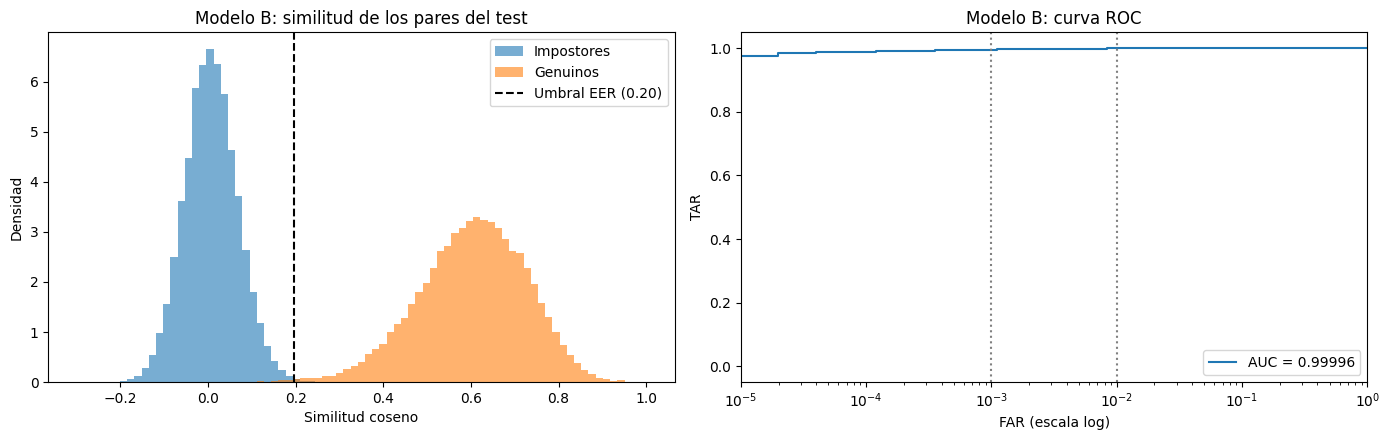

In [10]:
def graficar_verificacion(similitudes: np.ndarray, etiquetas: np.ndarray, metricas: dict, nombre: str):
    """Histograma de similitudes de genuinos e impostores y curva ROC."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

    bins = np.linspace(-0.3, 1, 80)
    axes[0].hist(similitudes[etiquetas == 0], bins=bins, alpha=0.6, density=True, label="Impostores")
    axes[0].hist(similitudes[etiquetas == 1], bins=bins, alpha=0.6, density=True, label="Genuinos")
    axes[0].axvline(metricas["Umbral EER"], color="black", linestyle="--",
                    label=f"Umbral EER ({metricas['Umbral EER']:.2f})")
    axes[0].set(title=f"{nombre}: similitud de los pares del test", xlabel="Similitud coseno", ylabel="Densidad")
    axes[0].legend()

    far, tar, _ = metricas["curva"]
    axes[1].plot(far, tar, label=f"AUC = {metricas['AUC']:.5f}")
    for objetivo in (1e-2, 1e-3):
        axes[1].axvline(objetivo, color="gray", linestyle=":")
    axes[1].set(xscale="log", xlim=(1e-5, 1), title=f"{nombre}: curva ROC", xlabel="FAR (escala log)", ylabel="TAR")
    axes[1].legend(loc="lower right")

    plt.tight_layout()
    plt.show()


graficar_verificacion(similitudes_b_test, etiquetas_test, verificacion_b, "Modelo B")

En el histograma, las similitudes de los impostores se concentran cerca de 0 y las de los genuinos alrededor de 0,6, con muy poca superposición entre las dos. En la ROC, el TAR queda por encima de 0,97 en todo el rango, incluso en el FAR más chico que podemos medir con 50.000 impostores (un solo impostor aceptado, 2e-5). Las líneas punteadas marcan los FAR de 1e-2 y 1e-3.

### c) Elección del umbral

Hacemos esta parte antes que la identificación porque la identificación necesita el umbral para decidir qué consultas son `unknown`. El umbral lo elegimos con la validación, y en el test solo lo aplicamos.

Podríamos usar el umbral del EER de la verificación, pero ese umbral equilibra los errores cuando se compara una foto contra otra. La app compara cada consulta contra todas las fotos registradas y se queda con la más parecida, así que a un desconocido le alcanza con parecerse a una sola de ellas para recibir un nombre. Con cientos de fotos en la galería, un FAR chico por comparación se convierte en un FAR mucho más grande por consulta.

Por eso calibramos el umbral simulando la app sobre la validación, que tiene su propia galería, consultas de personas registradas y consultas de desconocidos. Para cada consulta buscamos la foto de la galería más parecida, igual que `FaceService.identify`, y para cada umbral medimos:

- FAR de la app: porcentaje de consultas de desconocidos que reciben un nombre.
- FRR de la app: porcentaje de consultas de personas registradas que reciben `unknown`.

Como criterio elegimos el umbral más bajo que deja el FAR de la app en 1% o menos. Preferimos que la app diga `unknown` de más antes que ponerle el nombre de otra persona a alguien que no está registrado.

In [11]:
def simular_app(df: pd.DataFrame, embeddings: np.ndarray) -> pd.DataFrame:
    """Busca para cada consulta la foto más parecida de la galería, como hace la app."""
    es_galeria = (df["role_open_set"] == "gallery").to_numpy()
    similitudes = embeddings[~es_galeria] @ embeddings[es_galeria].T  # consultas x galería

    consultas = df[~es_galeria].copy()
    consultas["score"] = similitudes.max(axis=1)
    consultas["prediccion"] = df.loc[es_galeria, "identity"].to_numpy()[similitudes.argmax(axis=1)]
    consultas["desconocido"] = consultas["role_open_set"] == "probe_unknown"
    return consultas


val = splits[splits["split_open_set"] == "val"].reset_index(drop=True)
embeddings_b_val = embeddings_b[val["emb_idx"].to_numpy()]
consultas_b_val = simular_app(val, embeddings_b_val)

print(f"Fotos en la galería de validación: {(val['role_open_set'] == 'gallery').sum()}")
print(f"Consultas: {len(consultas_b_val)} ({(~consultas_b_val['desconocido']).sum()} de personas registradas "
      f"y {consultas_b_val['desconocido'].sum()} de desconocidos)")

Fotos en la galería de validación: 357
Consultas: 3437 (2691 de personas registradas y 746 de desconocidos)


Cada consulta se compara contra las 357 fotos de la galería de validación. Hay 746 consultas de desconocidos, así que un FAR de 1% equivale a 7 consultas. Es una estimación con pocos casos: un desconocido más o menos aceptado mueve el FAR en 0,13%.

Calculamos el FAR y el FRR de la app para una grilla de umbrales y elegimos el umbral según el criterio. Lo redondeamos hacia arriba a dos decimales para configurarlo en el `.env`. Redondear hacia arriba hace el umbral un poco más estricto, así que el FAR sigue cumpliendo el objetivo.

En el gráfico marcamos también el umbral del EER de la verificación (calculado con pares de validación) y el valor provisorio que tiene hoy la app (`SIMILARITY_THRESHOLD=0.55`), para comparar.

,Umbral,FAR app (%),FRR app (%)
,,,
Umbral elegido,0.31,0.80,0.19
EER verificación,0.19,53.62,0.00
Valor actual de la app,0.55,0.00,15.01


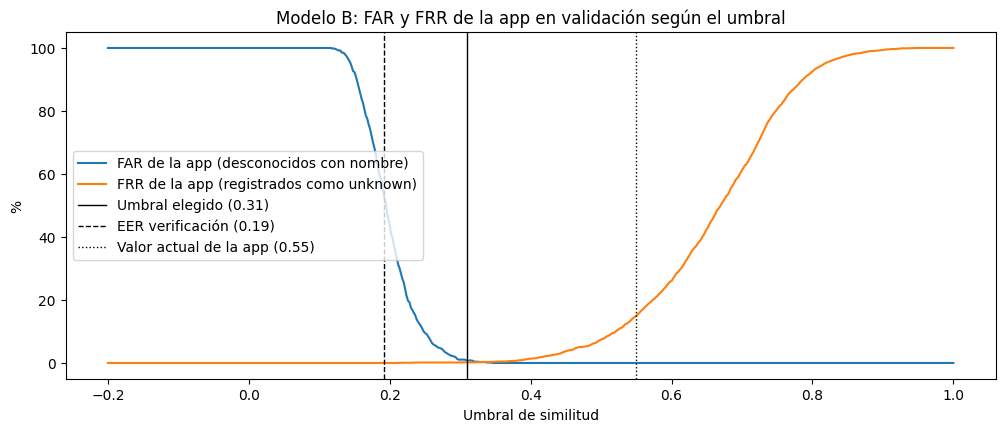

In [12]:
FAR_OBJETIVO = 0.01


def curvas_app(consultas: pd.DataFrame, umbrales: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """FAR y FRR de la app para cada umbral."""
    score_desc = consultas.loc[consultas["desconocido"], "score"].to_numpy()
    score_reg = consultas.loc[~consultas["desconocido"], "score"].to_numpy()
    far = (score_desc[None, :] >= umbrales[:, None]).mean(axis=1)
    frr = (score_reg[None, :] < umbrales[:, None]).mean(axis=1)
    return far, frr


def elegir_umbral(consultas: pd.DataFrame, far_objetivo: float = FAR_OBJETIVO) -> float:
    """Umbral más bajo (redondeado hacia arriba a dos decimales) con FAR de la app <= far_objetivo."""
    candidatos = np.round(np.arange(-1, 1.001, 0.01), 2)
    far, _ = curvas_app(consultas, candidatos)
    return float(candidatos[np.argmax(far <= far_objetivo)])


umbral_b = elegir_umbral(consultas_b_val)

# Umbral del EER de la verificación, con pares de validación
par_a_val, par_b_val, etiquetas_val = generar_pares(val)
umbral_eer_b_val = metricas_verificacion(similitudes_pares(embeddings_b_val, par_a_val, par_b_val), etiquetas_val)["Umbral EER"]

umbrales = np.linspace(-0.2, 1, 601)
far_app, frr_app = curvas_app(consultas_b_val, umbrales)
comparacion = {"Umbral elegido": umbral_b, "EER verificación": umbral_eer_b_val, "Valor actual de la app": 0.55}

filas = []
for nombre, u in comparacion.items():
    far_u, frr_u = curvas_app(consultas_b_val, np.array([u]))
    filas.append({"": nombre, "Umbral": round(u, 2), "FAR app (%)": far_u[0] * 100, "FRR app (%)": frr_u[0] * 100})
display(pd.DataFrame(filas).set_index("").round(2))

plt.figure(figsize=(12, 4.5))
plt.plot(umbrales, far_app * 100, label="FAR de la app (desconocidos con nombre)")
plt.plot(umbrales, frr_app * 100, label="FRR de la app (registrados como unknown)")
for (nombre, u), estilo in zip(comparacion.items(), ["-", "--", ":"]):
    plt.axvline(u, color="black", linestyle=estilo, linewidth=1, label=f"{nombre} ({u:.2f})")
plt.xlabel("Umbral de similitud")
plt.ylabel("%")
plt.title("Modelo B: FAR y FRR de la app en validación según el umbral")
plt.legend()
plt.show()

Con este criterio el umbral queda en 0,31. En validación, 6 de los 746 desconocidos (0,8%) reciben un nombre, y solo el 0,19% de las consultas de personas registradas queda como `unknown`.

Con el umbral del EER de la verificación (0,19), más de la mitad de los desconocidos (53,6%) recibiría el nombre de alguien registrado. Esto confirma que el EER no sirve para elegir el umbral de la app. Con el valor que tiene hoy la app (0,55) ningún desconocido recibe un nombre, pero el 15% de las consultas de personas registradas no se reconoce.

En el gráfico se ve que entre 0,31 y 0,40 los dos errores quedan por debajo del 1,5%. Elegimos el extremo más bajo de esa zona porque es el que menos rechaza a las personas registradas y cumple el objetivo. Este es el umbral que usamos en la identificación del test y el que va a ir al `.env` de la app si elegimos el modelo B.

### b) Identificación

Ahora evaluamos la identificación en el test, con el umbral de 0,31 que elegimos en validación y sin cambiarlo. La galería del test tiene 3 fotos por cada una de las 120 personas registradas, y las consultas son el resto de sus fotos más las de las 30 personas que nunca se registran.

Para cada consulta ordenamos a las personas registradas según la similitud con su foto más parecida de la galería. Es el mismo criterio que la app, que se queda con el embedding más parecido de todos los registrados.

In [13]:
def ranking_identidades(df: pd.DataFrame, embeddings: np.ndarray) -> tuple[pd.DataFrame, np.ndarray, np.ndarray]:
    """Similitud de cada consulta con cada persona registrada (su foto más parecida de la galería)."""
    es_galeria = (df["role_open_set"] == "gallery").to_numpy()
    similitudes = embeddings[~es_galeria] @ embeddings[es_galeria].T  # consultas x fotos de galería

    ids_galeria = df.loc[es_galeria, "identity"].to_numpy()
    registrados = np.unique(ids_galeria)
    por_persona = np.stack([similitudes[:, ids_galeria == i].max(axis=1) for i in registrados], axis=1)

    consultas = df[~es_galeria].reset_index(drop=True)
    return consultas, registrados, por_persona


consultas_test, registrados_test, similitud_b_test = ranking_identidades(test, embeddings_b_test)
print(f"Personas registradas: {len(registrados_test)} | Consultas: {len(consultas_test)}")

Personas registradas: 120 | Consultas: 3572


Hay 3.572 consultas para comparar contra las 120 personas registradas: 2.806 de personas registradas y 766 de desconocidos.

Primero medimos Top-1 y Top-5 con las consultas de personas registradas. Una consulta es acierto en Top-k si la persona correcta está entre las k primeras del ranking. Estas dos métricas no usan el umbral: miden si el modelo encuentra a la persona correcta entre las registradas.

In [14]:
def top_k(consultas: pd.DataFrame, registrados: np.ndarray, similitud: np.ndarray, k: int) -> float:
    """Porcentaje de consultas de registrados con la persona correcta entre las k más parecidas."""
    conocidas = (consultas["role_open_set"] == "probe_known").to_numpy()
    mejores_k = registrados[np.argsort(-similitud[conocidas], axis=1)[:, :k]]
    return (mejores_k == consultas.loc[conocidas, "identity"].to_numpy()[:, None]).any(axis=1).mean()


for k in (1, 5):
    print(f"Top-{k}: {100 * top_k(consultas_test, registrados_test, similitud_b_test, k):.2f}%")

Top-1: 100.00%
Top-5: 100.00%


El modelo B acierta el 100% en Top-1 y en Top-5: en todas las consultas de personas registradas, la persona más parecida es la correcta. Como el Top-1 ya es 100%, el Top-5 no puede agregar nada en este caso.

Ahora aplicamos el umbral, como la app: si la similitud con la persona más parecida es menor a 0,31 la respuesta es `unknown`, y si no, el nombre de esa persona. Con eso cada consulta termina en uno de cinco resultados posibles, tres para las personas registradas y dos para los desconocidos.

In [15]:
def responder(registrados: np.ndarray, similitud: np.ndarray, umbral: float) -> np.ndarray:
    """Respuesta de la app para cada consulta: la persona más parecida o -1 (unknown)."""
    mejor = similitud.argmax(axis=1)
    return np.where(similitud.max(axis=1) >= umbral, registrados[mejor], -1)


def resultados_identificacion(consultas: pd.DataFrame, respuestas: np.ndarray) -> pd.Series:
    """Cuántas consultas terminan en cada uno de los cinco resultados posibles."""
    desconocido = (consultas["role_open_set"] == "probe_unknown").to_numpy()
    real = consultas["identity"].to_numpy()
    resultado = np.select(
        [~desconocido & (respuestas == real),
         ~desconocido & (respuestas == -1),
         ~desconocido,
         desconocido & (respuestas == -1)],
        ["Registrado: nombre correcto",
         "Registrado: unknown",
         "Registrado: nombre equivocado",
         "Desconocido: unknown"],
        "Desconocido: recibe un nombre")
    return pd.Series(resultado).value_counts()


respuestas_b_test = responder(registrados_test, similitud_b_test, umbral_b)
conteo = resultados_identificacion(consultas_test, respuestas_b_test)
total = np.where(conteo.index.str.startswith("Registrado"), (consultas_test["role_open_set"] == "probe_known").sum(),
                 (consultas_test["role_open_set"] == "probe_unknown").sum())
pd.DataFrame({"Consultas": conteo, "% de su grupo": (100 * conteo / total).round(2)})

,Consultas,% de su grupo
Registrado: nombre correcto,2798,99.71
Desconocido: unknown,760,99.22
Registrado: unknown,8,0.29
Desconocido: recibe un nombre,6,0.78


El 99,71% de las consultas de personas registradas recibe el nombre correcto y ninguna recibe el nombre de otra persona. Los únicos errores con personas registradas son 8 consultas (0,29%) que quedaron por debajo del umbral y recibieron `unknown`.

De los desconocidos, 760 de 766 (99,22%) se rechazan correctamente y 6 (0,78%) reciben un nombre. Ese 0,78% está cerca del 0,8% que medimos en validación y cumple el objetivo de 1%, aunque en el test son otras personas. El umbral elegido en validación se comporta igual en el test.

Con las respuestas calculamos precision, recall y F1 de cada persona registrada y los promediamos en forma macro, donde cada persona pesa lo mismo sin importar cuántas fotos tenga. Incluimos las consultas de desconocidos: si la app le da a un desconocido el nombre de Ana, eso baja la precision de Ana. Y si una consulta de Ana termina en `unknown`, eso baja su recall.

In [16]:
reales_b = np.where(consultas_test["role_open_set"] == "probe_unknown", -1, consultas_test["identity"])
precision, recall, f1, _ = precision_recall_fscore_support(reales_b, respuestas_b_test, labels=registrados_test,
                                                            average="macro", zero_division=0)
print(f"Precision macro: {100 * precision:.2f}% | Recall macro: {100 * recall:.2f}% | F1 macro: {100 * f1:.2f}%")

Precision macro: 99.80% | Recall macro: 99.73% | F1 macro: 99.76%


Como el modelo no confunde a ninguna persona registrada con otra, la precision solo baja por los 6 desconocidos que recibieron un nombre y el recall por las 8 consultas que quedaron como `unknown`. Las tres métricas quedan cerca del 99,8%.

Con 120 personas registradas, la matriz de confusión sería de 121×121 (contando `unknown`) y no se podría leer. En su lugar listamos los errores: qué persona era y qué respondió la app.

In [17]:
def errores_identificacion(consultas: pd.DataFrame, respuestas: np.ndarray) -> pd.DataFrame:
    """Pares (persona real, respuesta) de las consultas mal respondidas, ordenados por cantidad."""
    real = np.where(consultas["role_open_set"] == "probe_unknown", "desconocido", consultas["identity"].astype(str))
    respuesta = np.where(respuestas == -1, "unknown", respuestas.astype(str))
    mal = ~((real == respuesta) | ((real == "desconocido") & (respuesta == "unknown")))
    return (pd.DataFrame({"Persona real": real[mal], "Respuesta": respuesta[mal]})
            .value_counts().rename("Consultas").reset_index())


errores_b = errores_identificacion(consultas_test, respuestas_b_test)
errores_b

,Persona real,Respuesta,Consultas
0,desconocido,3229,2
1,desconocido,675,2
2,desconocido,4314,1
3,8956,unknown,1
4,desconocido,1839,1
5,82,unknown,1
6,8962,unknown,1
7,545,unknown,1
8,264,unknown,1
9,5948,unknown,1


Hay 14 errores en total. Seis son desconocidos que recibieron un nombre (las personas 3229 y 675 aparecen dos veces como respuesta) y ocho son consultas de personas registradas que quedaron como `unknown`, cada una de una persona distinta. No hay ninguna consulta de una persona registrada confundida con otra. Estos casos los vamos a mirar con sus imágenes en el análisis de errores.